## NB07 — Análise Exploratória de Dados (EDA)

**Entrada:** `data/processed/dataset_ml_clean.csv` — 76.218 linhas × 27 features, 0 NaN (gerado pelo NB06)

**Objetivo:** Compreender a estrutura, distribuições, padrões e anomalias do dataset antes de aplicar os modelos
de detecção de anomalias (Isolation Forest, LOF, One-Class SVM no NB08).
A EDA responde perguntas concretas:
- Qual é o perfil de preço das propostas? Onde estão os desvios mais extremos?
- O volume de licitações varia ao longo do tempo? Existe sazonalidade por mês ou trimestre?
- O ciclo eleitoral se reflete nos dados? Há mais contratações em períodos pré-eleitorais?
- Fornecedores de fora de PE dominam determinadas modalidades ou órgãos?
- Quais modalidades concentram maior risco de anomalia pelo perfil das propostas?

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Setup OK')

Setup OK


---
### 1. Carregamento e Visão Geral

In [28]:
df = pd.read_csv('data/processed/dataset_ml_clean.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
print(f'\nValores ausentes: {df.isnull().sum().sum()} (esperado: 0)')

df.head()

Shape: (76218, 25)

Colunas (25):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidadeNome', 'porte', 'cnae_fiscal', 'descricao_situacao_cadastral']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_item_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre                         int64
dia_semana                        int64
dias_para_eleica

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,...,fornecedor_fora_pe,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral
0,2030715000112,2023,1,1,44051659000142,-0.354518,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
1,2030715000112,2023,3,1,44051659000142,-0.019704,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
2,508903000188,2022,324,1,32212672000157,0.000000,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
3,2030715000112,2023,2,1,46941329000158,-0.006719,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
4,15126437000143,2022,846,1,2515391000374,0.000000,1,1,2023,1,...,1,1,8.659822,0,0,0,4,0,-1,1


In [29]:
df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
orgaoEntidadeCnpj,76218.0,8.156092e+12,9.239763e+12,3.816600e+10,3.480030e+11,3.944290e+11,3.944520e+11,9.773169e+12,1.135814e+13,2.699456e+13,3.587281e+13,4.235748e+13
anoCompraPncp,76218.0,2.023680e+03,4.812236e-01,2.022000e+03,2.023000e+03,2.023000e+03,2.023000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.025000e+03
sequencialCompraPncp,76218.0,3.682143e+03,5.619679e+03,1.000000e+00,1.000000e+00,6.000000e+00,7.000000e+01,5.580000e+02,4.106000e+03,1.560000e+04,2.123600e+04,2.256900e+04
numeroItem,76218.0,5.755190e+01,8.431118e+01,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00,2.400000e+01,7.300000e+01,2.420000e+02,4.140000e+02,5.030000e+02
cnpj_forn_norm,76218.0,2.639993e+13,2.022847e+14,0.000000e+00,0.000000e+00,8.521065e+09,8.778201e+12,2.404646e+13,4.126394e+13,5.350689e+13,7.144367e+13,5.562232e+16
desvio_item_estimado,76218.0,-2.353918e-01,5.384317e-01,-1.000000e+00,-9.999000e-01,-7.275058e-01,-4.135837e-01,-1.666667e-01,0.000000e+00,0.000000e+00,0.000000e+00,9.275000e+01
n_propostas_item,76218.0,1.485581e+00,2.982230e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,1.200000e+01,4.200000e+01
fornecedor_unico,76218.0,8.973864e-01,3.034555e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
ano,76218.0,2.023723e+03,4.473664e-01,2.023000e+03,2.023000e+03,2.023000e+03,2.023000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03
mes,76218.0,7.415046e+00,3.121319e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+00,8.000000e+00,1.000000e+01,1.200000e+01,1.200000e+01,1.200000e+01


---
### 2. Visão Geral: Cardinalidades e Entidades

- **orgaoEntidadeCnpj**: número de órgãos compradores distintos no dataset
- **cnpj_forn_norm**: número de fornecedores únicos
- **modalidadeNome**: número de modalidades licitatórias presentes
- **cnae_fiscal**: diversidade de setores econômicos dos fornecedores

In [30]:
cardinalidade = pd.DataFrame({
    'unicos': df.nunique(),
    'pct_total': (df.nunique() / len(df) * 100).round(2)
}).sort_values('unicos', ascending=False)

print('Cardinalidade por coluna:')
print(cardinalidade.to_string())

print('\n--- Resumo de entidades ---')
n_orgaos = df['orgaoEntidadeCnpj'].nunique()
n_forn   = df['cnpj_forn_norm'].nunique()
n_contr  = df.groupby(['orgaoEntidadeCnpj','anoCompraPncp','sequencialCompraPncp']).ngroups
print(f'Orgaos compradores:  {n_orgaos:>6,}')
print(f'Fornecedores unicos: {n_forn:>6,}')
print(f'Contratacoes:        {n_contr:>6,}')
print(f'Propostas (linhas):  {len(df):>6,}')

Cardinalidade por coluna:
                              unicos  pct_total
desvio_item_estimado           43709      57.35
cnpj_forn_norm                  9447      12.39
idade_empresa_anos              7385       9.69
sequencialCompraPncp            4156       5.45
cnae_fiscal                      512       0.67
numeroItem                       503       0.66
dias_para_eleicao                474       0.62
orgaoEntidadeCnpj                103       0.14
n_propostas_item                  21       0.03
mes                               12       0.02
dia_semana                         7       0.01
modalidadeNome                     6       0.01
descricao_situacao_cadastral       5       0.01
porte                              4       0.01
trimestre                          4       0.01
anoCompraPncp                      4       0.01
fornecedor_unico                   2       0.00
ano                                2       0.00
fornecedor_fora_pe                 2       0.00
pre_eleitoral_

---
### 3. Distribuições das Features Numéricas Contínuas

- **`desvio_item_estimado`**: desvio percentual do preço vencedor em relação ao teto unitário
  estimado no edital. Valor 0 = cobrou exatamente o estimado; valor 1 = 100% acima (sobrepreço);
  −1 = 100% abaixo (desconto). Sobrepreços extremos são candidatos diretos a anomalia.
- **`idade_empresa_anos`**: idade da empresa na data da proposta. Empresas muito novas em
  contratações de alto valor são sinal clássico de risco.
- **`dias_para_eleicao`**: distância em dias para a próxima eleição municipal.

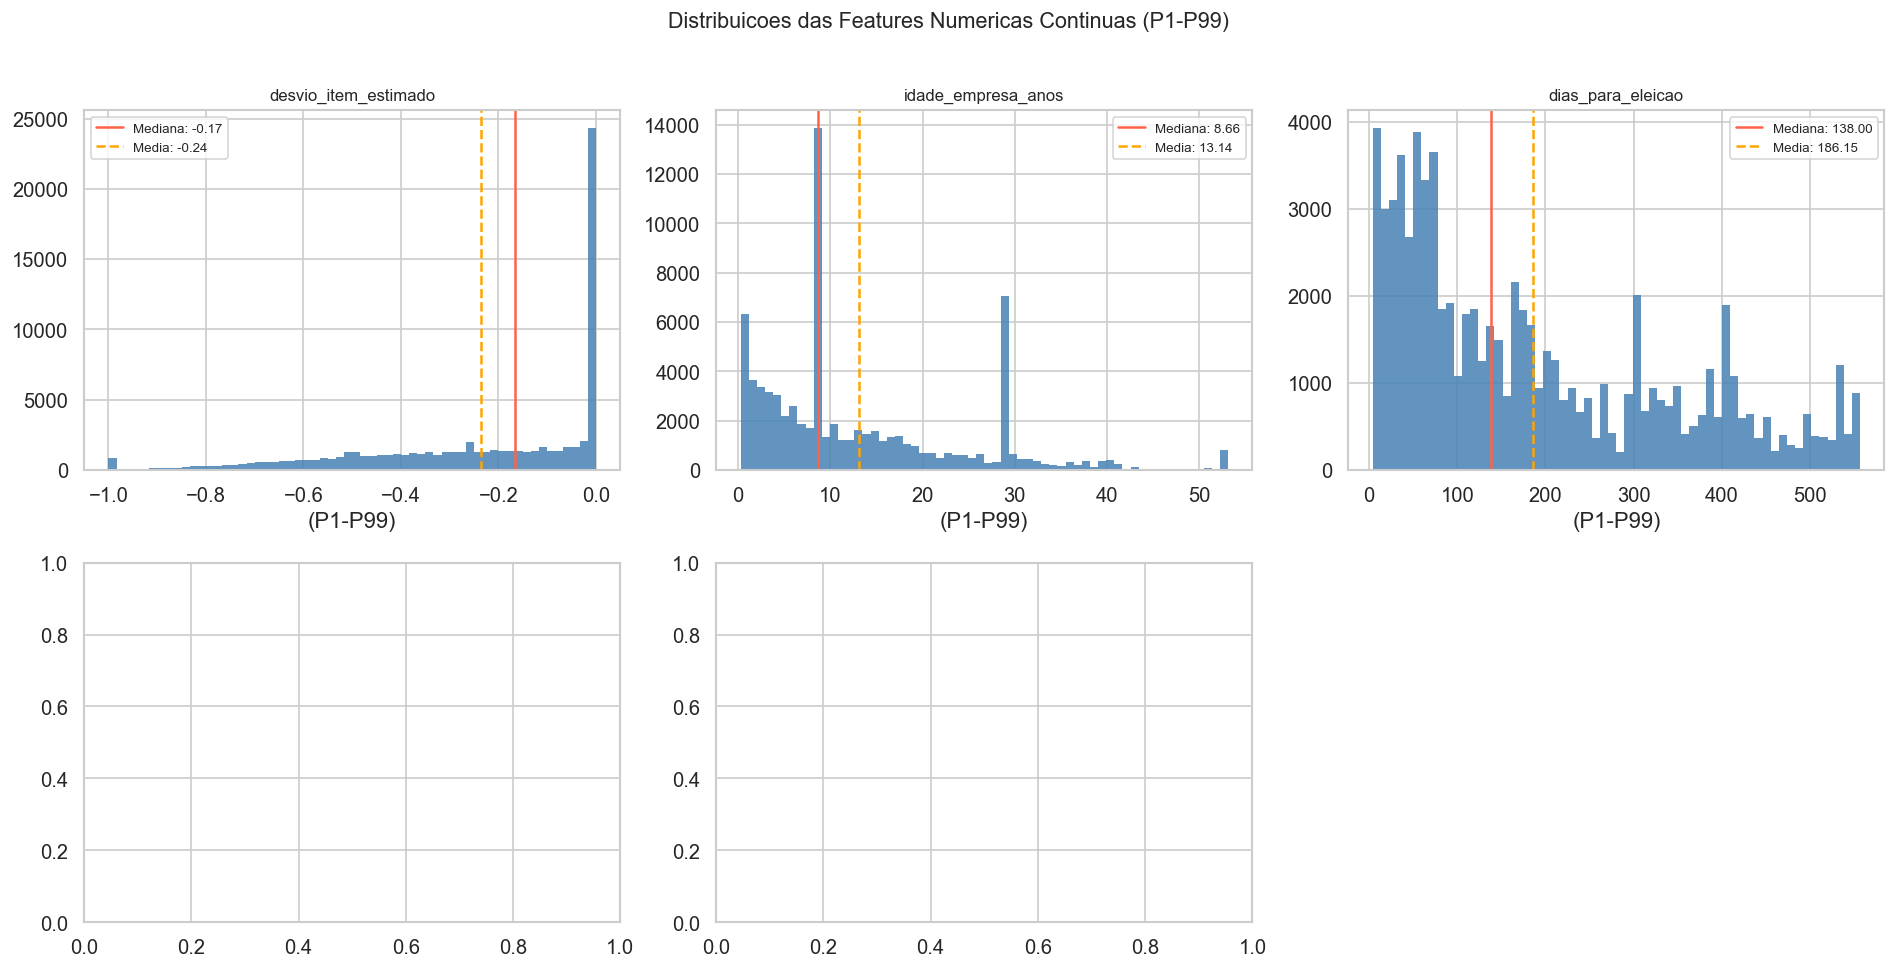

,desvio_item_estimado,idade_empresa_anos,dias_para_eleicao
count,76218.000,76218.000,76218.000
mean,-0.235,13.137,186.154
std,0.538,11.451,155.353
min,-1.000,0.000,1.000
1%,-1.000,0.285,4.000
5%,-0.728,0.780,13.000
25%,-0.414,4.486,57.000
50%,-0.167,8.660,138.000
75%,0.000,18.938,305.000
95%,0.000,33.198,500.000


In [31]:
numericas = ['desvio_item_estimado', 'idade_empresa_anos', 'dias_para_eleicao']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numericas):
    data = df[col].dropna()
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data_vis = data.clip(p1, p99)
    axes[i].hist(data_vis, bins=60, color='steelblue', edgecolor='none', alpha=0.85)
    med_val = data.median()
    mean_val = data.mean()
    axes[i].axvline(med_val, color='tomato', linewidth=1.5, label=f'Mediana: {med_val:.2f}')
    axes[i].axvline(mean_val, color='orange', linewidth=1.5, linestyle='--', label=f'Media: {mean_val:.2f}')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('(P1-P99)')
    axes[i].legend(fontsize=8)

axes[5].set_visible(False)
plt.suptitle('Distribuicoes das Features Numericas Continuas (P1-P99)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

df[numericas].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).round(3)

---
### 4. Distribuições das Features Categóricas e Binárias

- **`fornecedor_unico`**: 1 se apenas um vencedor registrado no item (89,7%). Desequilíbrio
  parcialmente artefato da API PNCP (retorna só vencedor).
- **`fornecedor_fora_pe`**: 1 se fornecedor é de outro estado (63,1%).
- **`tipo_fornecedor`**: 1 = pessoa jurídica (91%), 0 = pessoa física (9%).
- **`empresa_nova`**: 1 se empresa com < 1 ano de existência na data da proposta.
- **`porte`**: ordinal — 0=desconhecido, 1=micro, 2=EPP, 3=demais.
- **`modalidadeNome`**: modalidade licitatória (label-encoded no NB06).

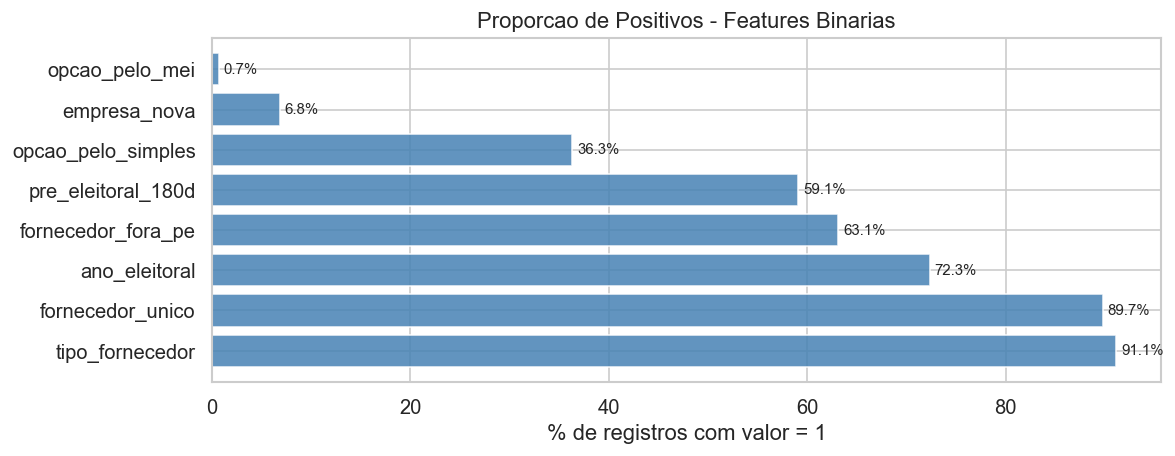

In [32]:
binarias = ['fornecedor_unico', 'fornecedor_fora_pe', 'tipo_fornecedor',
            'empresa_nova', 'ano_eleitoral', 'pre_eleitoral_180d',
            'opcao_pelo_mei', 'opcao_pelo_simples']

prop = df[binarias].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(prop.index, prop.values * 100, color='steelblue', alpha=0.85)
ax.set_xlabel('% de registros com valor = 1')
ax.set_title('Proporcao de Positivos - Features Binarias')
for bar, val in zip(bars, prop.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val*100:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

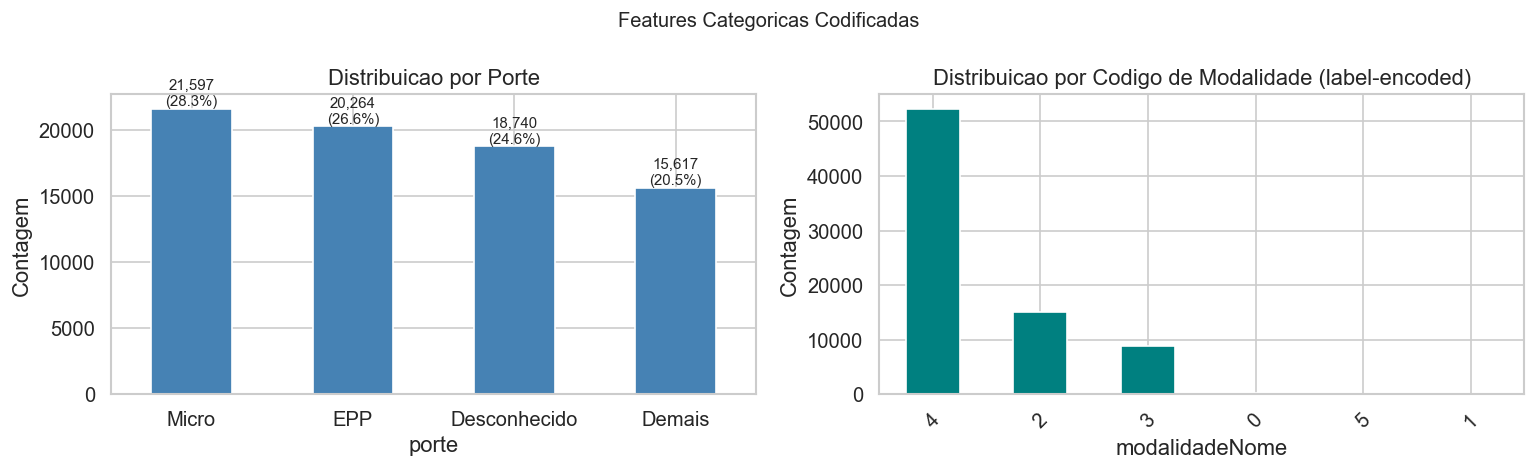

In [33]:
porte_labels = {0: 'Desconhecido', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
porte_counts = df['porte'].map(porte_labels).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

porte_counts.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Distribuicao por Porte')
axes[0].set_ylabel('Contagem')
for p in axes[0].patches:
    pct = p.get_height() / len(df) * 100
    axes[0].annotate(f'{p.get_height():,.0f}\n({pct:.1f}%)',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

df['modalidadeNome'].value_counts().plot(kind='bar', ax=axes[1], color='teal', rot=45)
axes[1].set_title('Distribuicao por Codigo de Modalidade (label-encoded)')
axes[1].set_ylabel('Contagem')

plt.suptitle('Features Categoricas Codificadas', fontsize=12)
plt.tight_layout()
plt.show()

---
### 5. Análise de Outliers de Preço

Sobrepreços e subpreços extremos:

1. **Thresholds de sobrepreço**: proporção de propostas com `desvio_item_estimado` > 0.5
   (50% acima do teto estimado), > 1.0 (dobro do estimado), > 2.0 (triplo).
2. **Top 20 outliers**: propostas com os maiores desvios para inspeção manual.
3. **Perfil dos outliers**: distribuição por porte, tipo de fornecedor e perfil de empresa
   — sinaliza quais combinações concentram maior risco.

In [34]:
thresholds_desvio = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

print('=== desvio_item_estimado ===')
for t in thresholds_desvio:
    n = (df['desvio_item_estimado'] > t).sum()
    pct = n / len(df) * 100
    print(f'  > {t}: {n:>8,} propostas ({pct:.2f}%)')

=== desvio_item_estimado ===
  > 0.1:      107 propostas (0.14%)
  > 0.5:       44 propostas (0.06%)
  > 1.0:       25 propostas (0.03%)
  > 2.0:       14 propostas (0.02%)
  > 5.0:        6 propostas (0.01%)
  > 10.0:        3 propostas (0.00%)


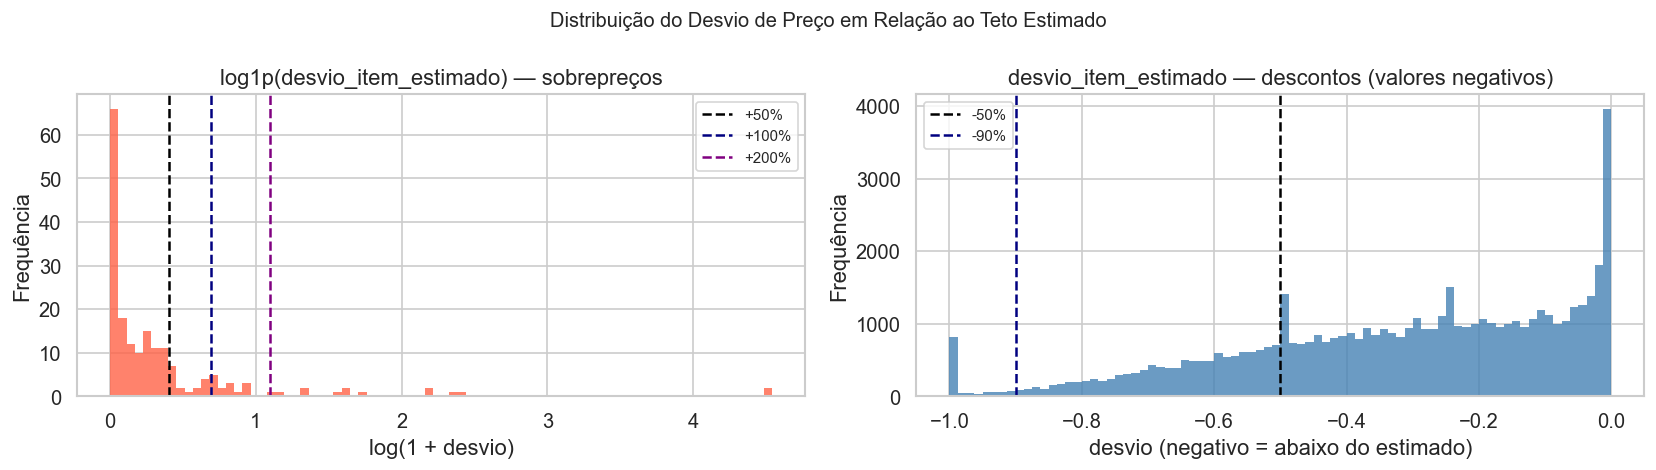

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sobrepreco = df.loc[df['desvio_item_estimado'] > 0, 'desvio_item_estimado']
axes[0].hist(np.log1p(sobrepreco), bins=80, color='tomato', alpha=0.8, edgecolor='none')
axes[0].set_title('log1p(desvio_item_estimado) — sobrepreços')
axes[0].set_xlabel('log(1 + desvio)')
axes[0].set_ylabel('Frequência')
axes[0].axvline(np.log1p(0.5), color='black', linestyle='--', label='+50%')
axes[0].axvline(np.log1p(1.0), color='navy', linestyle='--', label='+100%')
axes[0].axvline(np.log1p(2.0), color='purple', linestyle='--', label='+200%')
axes[0].legend(fontsize=9)

desconto = df.loc[df['desvio_item_estimado'] < 0, 'desvio_item_estimado']
axes[1].hist(desconto, bins=80, color='steelblue', alpha=0.8, edgecolor='none')
axes[1].set_title('desvio_item_estimado — descontos (valores negativos)')
axes[1].set_xlabel('desvio (negativo = abaixo do estimado)')
axes[1].set_ylabel('Frequência')
axes[1].axvline(-0.5, color='black', linestyle='--', label='-50%')
axes[1].axvline(-0.9, color='navy', linestyle='--', label='-90%')
axes[1].legend(fontsize=9)

plt.suptitle('Distribuição do Desvio de Preço em Relação ao Teto Estimado', fontsize=12)
plt.tight_layout()
plt.show()

In [36]:
# Top 20 outliers de sobrepreco
cols_top = ['orgaoEntidadeCnpj','anoCompraPncp','sequencialCompraPncp','numeroItem',
            'cnpj_forn_norm','desvio_item_estimado',
            'porte','tipo_fornecedor','empresa_nova']
outliers_preco = df.nlargest(20, 'desvio_item_estimado')[cols_top]
print('Top 20 propostas com maior sobrepreco:')
outliers_preco

Top 20 propostas com maior sobrepreco:


,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,porte,tipo_fornecedor,empresa_nova
16910,394452000103,2023,9953,95,7199135000177,92.750000,2,1,0
16902,394452000103,2023,9953,73,29868059000188,89.476190,3,1,0
32052,394502000144,2024,2623,2,52934421000193,10.473684,1,1,1
66346,26474056000171,2024,308,6,31978612000187,9.500000,0,1,0
45978,11674751000100,2024,5,19,13531477000145,8.083333,1,1,0
14626,394452000103,2023,12887,43,207275000109,8.065657,2,1,0
43901,394460000141,2024,857,1,23186928000108,4.787606,1,1,0
43180,11674777000158,2024,21,1,19703791000144,3.993037,3,1,0
14593,394452000103,2023,12887,10,207275000109,3.961538,2,1,0
14590,394452000103,2023,12887,7,207275000109,3.781250,2,1,0


Propostas com desvio > 100%: 25 (0.0%)


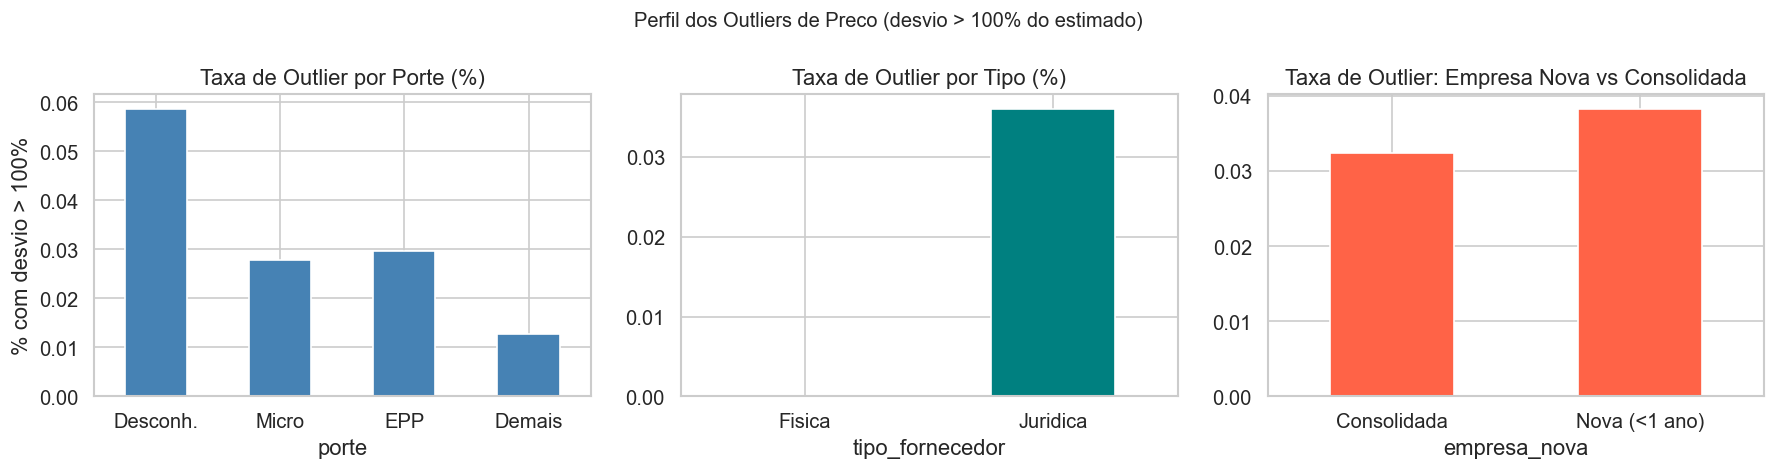

In [37]:
# Perfil dos outliers
df['outlier_preco'] = (df['desvio_item_estimado'] > 1.0).astype(int)
n_outliers = df['outlier_preco'].sum()
pct_outliers = df['outlier_preco'].mean() * 100
print(f'Propostas com desvio > 100%: {n_outliers:,} ({pct_outliers:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

porte_map = {0: 'Desconh.', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
taxa_porte = df.groupby('porte')['outlier_preco'].mean() * 100
taxa_porte.index = taxa_porte.index.map(porte_map)
taxa_porte.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Taxa de Outlier por Porte (%)')
axes[0].set_ylabel('% com desvio > 100%')

taxa_tipo = df.groupby('tipo_fornecedor')['outlier_preco'].mean() * 100
taxa_tipo.index = taxa_tipo.index.map({0: 'Fisica', 1: 'Juridica'})
taxa_tipo.plot(kind='bar', ax=axes[1], color='teal', rot=0)
axes[1].set_title('Taxa de Outlier por Tipo (%)')

taxa_nova = df.groupby('empresa_nova')['outlier_preco'].mean() * 100
taxa_nova.index = taxa_nova.index.map({0: 'Consolidada', 1: 'Nova (<1 ano)'})
taxa_nova.plot(kind='bar', ax=axes[2], color='tomato', rot=0)
axes[2].set_title('Taxa de Outlier: Empresa Nova vs Consolidada')

plt.suptitle('Perfil dos Outliers de Preco (desvio > 100% do estimado)', fontsize=12)
plt.tight_layout()
plt.show()

---
### 6. Sazonalidade Temporal

1. **Ciclo orçamentário**: órgãos públicos tendem a concentrar contratações no final do ano
   (novembro–dezembro) para executar o orçamento aprovado, e no início (fevereiro–março)
   após a aprovação do PPA/LOA.
2. **Ciclo eleitoral**: 2024 é ano eleitoral municipal — esperamos pico de contratações
   no período pré-eleitoral (jan–out/2024).
3. **Efeito dia da semana**: contratações publicadas na sexta-feira têm menor visibilidade
   pública, o que pode facilitar irregularidades.
4. **Transição legal**: aumento acentuado de contratações entre 2023 e 2024 reflete
   a adesão crescente ao novo regime jurídico.

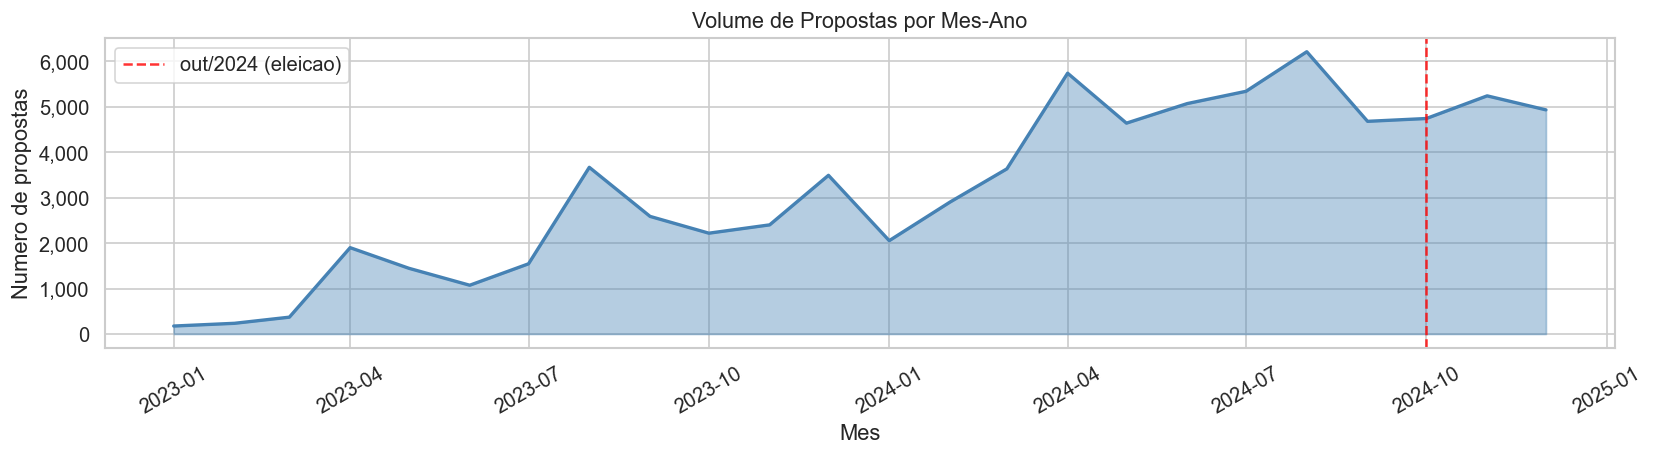

In [38]:
# Série temporal mensal
df['ano_mes'] = pd.to_datetime(df['ano'].astype(str) + '-' + df['mes'].astype(str).str.zfill(2) + '-01')
serie_temporal = df.groupby('ano_mes').size().reset_index(name='n_propostas')

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(serie_temporal['ano_mes'], serie_temporal['n_propostas'], alpha=0.4, color='steelblue')
ax.plot(serie_temporal['ano_mes'], serie_temporal['n_propostas'], color='steelblue', linewidth=2)
ax.axvline(pd.Timestamp('2024-10-01'), color='red', linestyle='--', alpha=0.8, label='out/2024 (eleicao)')
ax.set_title('Volume de Propostas por Mes-Ano', fontsize=13)
ax.set_xlabel('Mes')
ax.set_ylabel('Numero de propostas')
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

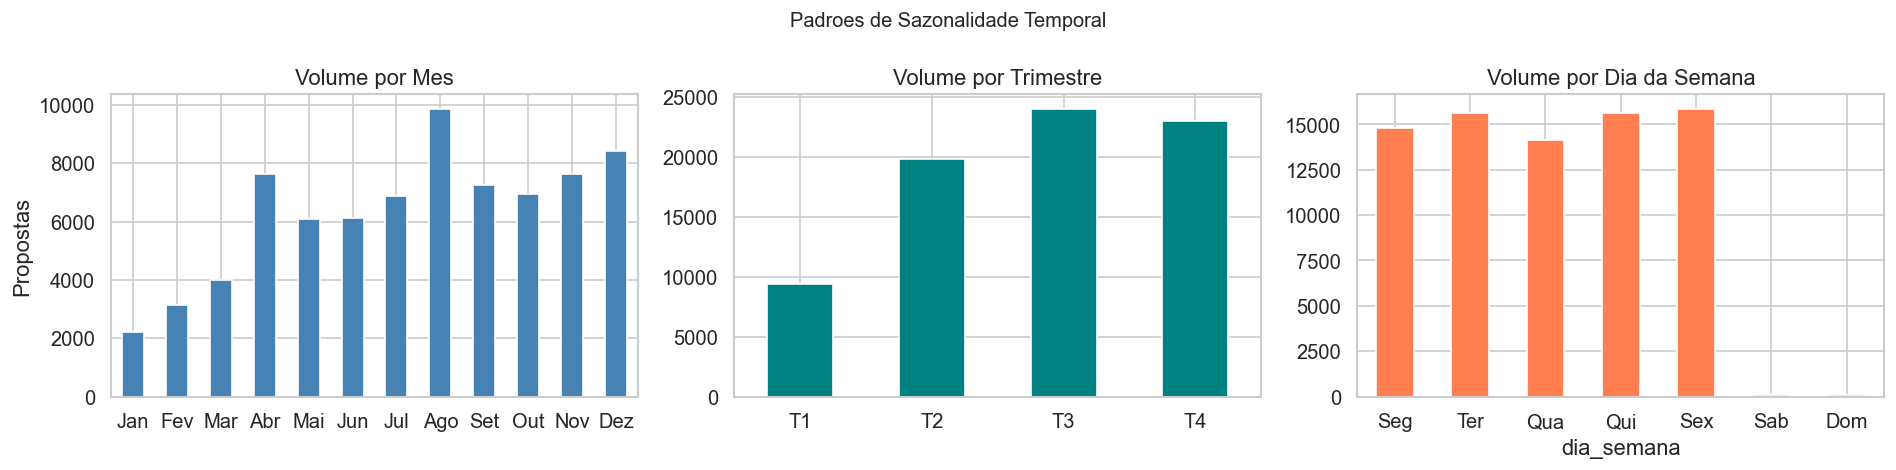

In [39]:
nomes_mes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

por_mes = df.groupby('mes').size()
por_mes.index = [nomes_mes[m-1] for m in por_mes.index]
por_mes.plot(kind='bar', ax=axes[0], color='steelblue', rot=0)
axes[0].set_title('Volume por Mes')
axes[0].set_ylabel('Propostas')

por_tri = df.groupby('trimestre').size()
por_tri.index = ['T' + str(i) for i in por_tri.index]
por_tri.plot(kind='bar', ax=axes[1], color='teal', rot=0)
axes[1].set_title('Volume por Trimestre')

por_dia = df.groupby('dia_semana').size()
dias_nomes = {0:'Seg',1:'Ter',2:'Qua',3:'Qui',4:'Sex',5:'Sab',6:'Dom'}
por_dia.index = por_dia.index.map(dias_nomes)
por_dia.plot(kind='bar', ax=axes[2], color='coral', rot=0)
axes[2].set_title('Volume por Dia da Semana')

plt.suptitle('Padroes de Sazonalidade Temporal', fontsize=12)
plt.tight_layout()
plt.show()

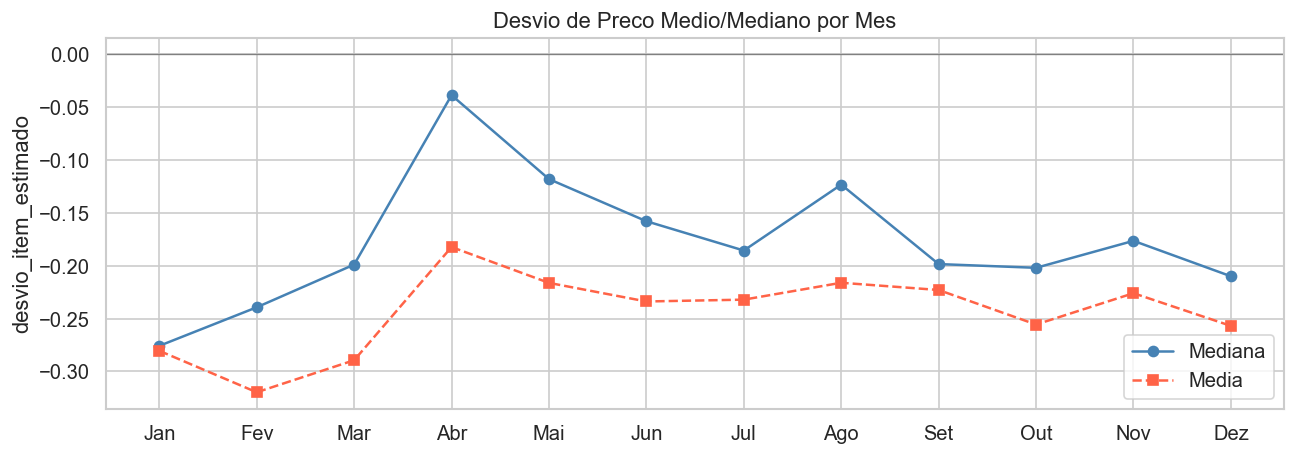

       mean  median     std
Jan -0.2806 -0.2759  0.2453
Fev -0.3198 -0.2394  0.3236
Mar -0.2895 -0.1989  0.3037
Abr -0.1823 -0.0386  0.2736
Mai -0.2163 -0.1180  0.2488
Jun -0.2339 -0.1579  0.2655
Jul -0.2321 -0.1856  0.2631
Ago -0.2161 -0.1232  0.2407
Set -0.2230 -0.1985  1.5357
Out -0.2557 -0.2020  0.2532
Nov -0.2260 -0.1765  0.2970
Dez -0.2570 -0.2100  0.2495


In [40]:
# Desvio de preco medio por mes
desvio_por_mes = df.groupby('mes')['desvio_item_estimado'].agg(['mean','median','std'])
desvio_por_mes.index = [nomes_mes[m-1] for m in desvio_por_mes.index]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(desvio_por_mes.index, desvio_por_mes['median'], marker='o', color='steelblue', label='Mediana')
ax.plot(desvio_por_mes.index, desvio_por_mes['mean'], marker='s', color='tomato',
        linestyle='--', label='Media')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Desvio de Preco Medio/Mediano por Mes')
ax.set_ylabel('desvio_item_estimado')
ax.legend()
plt.tight_layout()
plt.show()

print(desvio_por_mes.round(4).to_string())

---
### 7. Análise Eleitoral

Variáveis eleitorais no dataset:
- **`dias_para_eleicao`**: distância em dias para a eleição mais próxima (15/11/2020 ou 06/10/2024).
  Como o dataset cobre 2023–2024, reflete principalmente a eleição de outubro/2024.
- **`ano_eleitoral`**: 1 se a proposta foi em 2020 ou 2024.
- **`pre_eleitoral_180d`**: 1 se a proposta foi dentro de 180 dias antes de uma eleição
  (59,1% do dataset — artefato da concentração temporal em 2023–2024).


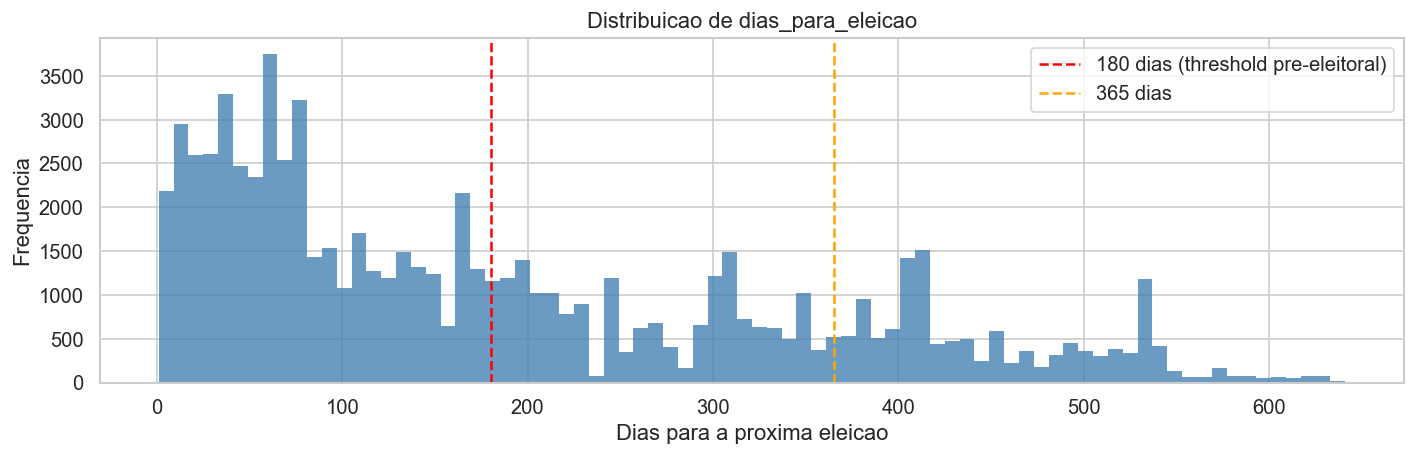

In [41]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(df['dias_para_eleicao'], bins=80, color='steelblue', alpha=0.8, edgecolor='none')
ax.axvline(180, color='red', linestyle='--', label='180 dias (threshold pre-eleitoral)')
ax.axvline(365, color='orange', linestyle='--', label='365 dias')
ax.set_title('Distribuicao de dias_para_eleicao')
ax.set_xlabel('Dias para a proxima eleicao')
ax.set_ylabel('Frequencia')
ax.legend()
plt.tight_layout()
plt.show()

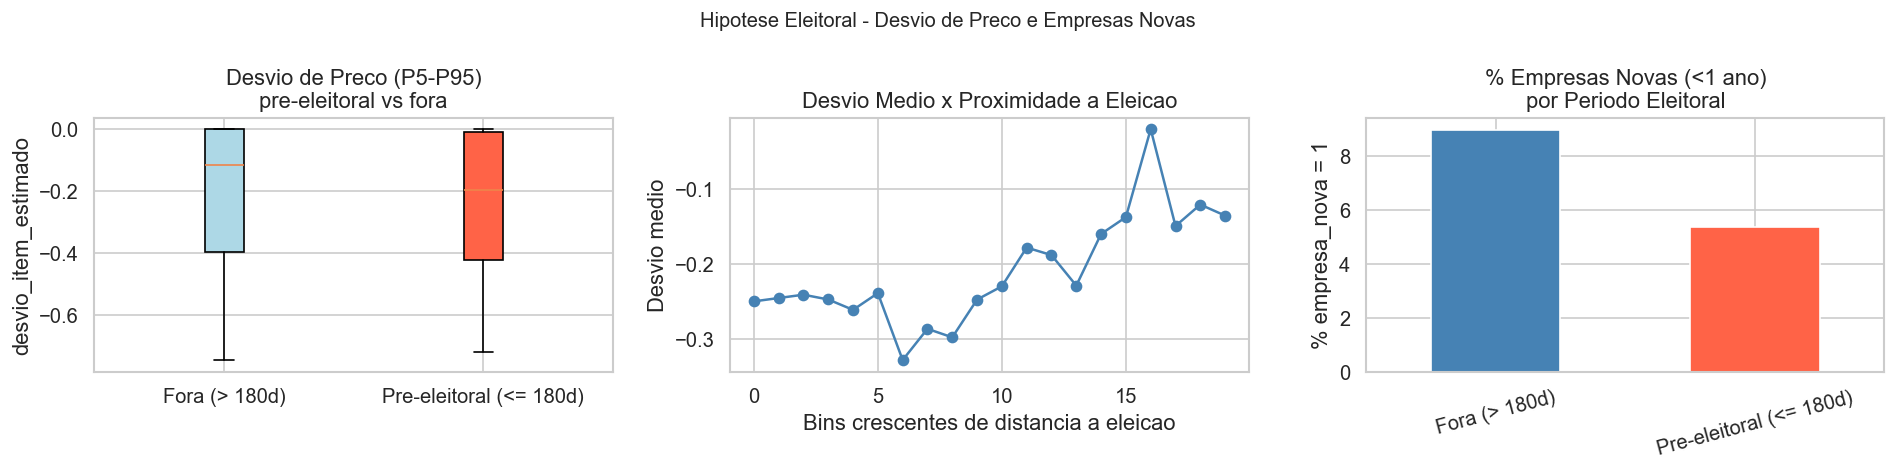

Mann-Whitney U (pre-eleitoral vs fora):
  U = 783043412  |  p-value = 0.0000
  Mediana fora:          -0.1162
  Mediana pre-eleitoral: -0.1977


In [42]:
labels_eleit = {0: 'Fora (> 180d)', 1: 'Pre-eleitoral (<= 180d)'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Boxplot desvio x pre_eleitoral_180d
grupos = df.groupby('pre_eleitoral_180d')['desvio_item_estimado']
data_box = [grupos.get_group(k) for k in [0, 1]]
bp = axes[0].boxplot(data_box, labels=[labels_eleit[0], labels_eleit[1]],
                     whis=[5, 95], showfliers=False, patch_artist=True)
for patch, color in zip(bp['boxes'], ['lightblue', 'tomato']):
    patch.set_facecolor(color)
axes[0].set_title('Desvio de Preco (P5-P95)\npre-eleitoral vs fora')
axes[0].set_ylabel('desvio_item_estimado')

# Desvio medio em bins de dias_para_eleicao
df['dias_bin'] = pd.cut(df['dias_para_eleicao'], bins=20)
desvio_por_dias = df.groupby('dias_bin', observed=True)['desvio_item_estimado'].mean()
axes[1].plot(range(len(desvio_por_dias)), desvio_por_dias.values,
             marker='o', color='steelblue', linewidth=1.5)
axes[1].set_title('Desvio Medio x Proximidade a Eleicao')
axes[1].set_xlabel('Bins crescentes de distancia a eleicao')
axes[1].set_ylabel('Desvio medio')

# Taxa de empresa nova x pre-eleitoral
taxa_nova_eleit = df.groupby('pre_eleitoral_180d')['empresa_nova'].mean() * 100
taxa_nova_eleit.index = [labels_eleit[0], labels_eleit[1]]
taxa_nova_eleit.plot(kind='bar', ax=axes[2], color=['steelblue', 'tomato'], rot=15)
axes[2].set_title('% Empresas Novas (<1 ano)\npor Periodo Eleitoral')
axes[2].set_ylabel('% empresa_nova = 1')

plt.suptitle('Hipotese Eleitoral - Desvio de Preco e Empresas Novas', fontsize=12)
plt.tight_layout()
plt.show()

# Teste estatistico Mann-Whitney U
g0 = df.loc[df['pre_eleitoral_180d'] == 0, 'desvio_item_estimado']
g1 = df.loc[df['pre_eleitoral_180d'] == 1, 'desvio_item_estimado']
stat_u, pval_u = stats.mannwhitneyu(g0, g1, alternative='two-sided')
print('Mann-Whitney U (pre-eleitoral vs fora):')
print(f'  U = {stat_u:.0f}  |  p-value = {pval_u:.4f}')
print(f'  Mediana fora:          {g0.median():.4f}')
print(f'  Mediana pre-eleitoral: {g1.median():.4f}')

---
### 8. Análise Geográfica

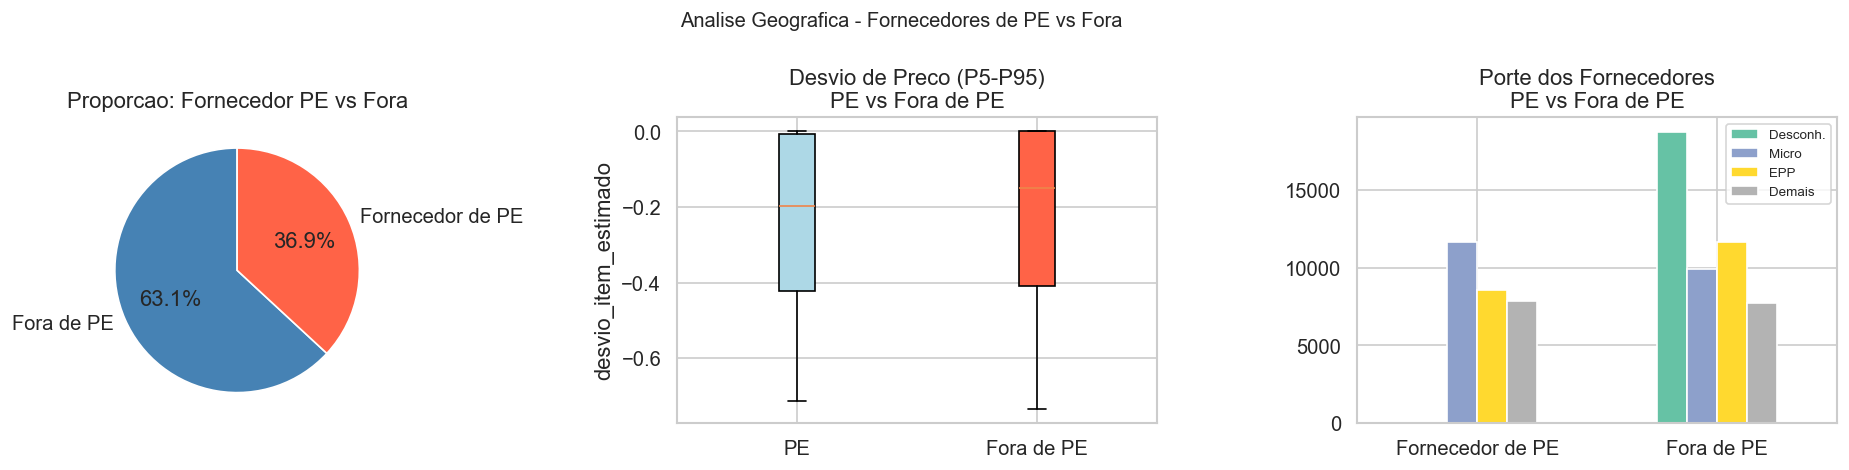

Mediana desvio PE:      -0.1976
Mediana desvio Fora PE: -0.1490
Mann-Whitney p-value:   0.0000


In [43]:
fora_pe_labels = {0: 'Fornecedor de PE', 1: 'Fora de PE'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

fora_pe_counts = df['fornecedor_fora_pe'].value_counts()
axes[0].pie(fora_pe_counts.values,
            labels=[fora_pe_labels[k] for k in fora_pe_counts.index],
            autopct='%1.1f%%', colors=['steelblue', 'tomato'], startangle=90)
axes[0].set_title('Proporcao: Fornecedor PE vs Fora')

g_pe   = df.loc[df['fornecedor_fora_pe'] == 0, 'desvio_item_estimado']
g_fora = df.loc[df['fornecedor_fora_pe'] == 1, 'desvio_item_estimado']
bp = axes[1].boxplot([g_pe, g_fora], labels=['PE', 'Fora de PE'],
                     whis=[5,95], showfliers=False, patch_artist=True)
for patch, c in zip(bp['boxes'], ['lightblue', 'tomato']):
    patch.set_facecolor(c)
axes[1].set_title('Desvio de Preco (P5-P95)\nPE vs Fora de PE')
axes[1].set_ylabel('desvio_item_estimado')

porte_map2 = {0: 'Desconh.', 1: 'Micro', 2: 'EPP', 3: 'Demais'}
porte_geo = df.groupby(['fornecedor_fora_pe', 'porte']).size().unstack(fill_value=0)
porte_geo.index = [fora_pe_labels[k] for k in porte_geo.index]
porte_geo.columns = [porte_map2.get(c, str(c)) for c in porte_geo.columns]
porte_geo.plot(kind='bar', ax=axes[2], rot=0, colormap='Set2')
axes[2].set_title('Porte dos Fornecedores\nPE vs Fora de PE')
axes[2].legend(fontsize=8)

plt.suptitle('Analise Geografica - Fornecedores de PE vs Fora', fontsize=12)
plt.tight_layout()
plt.show()

print(f'Mediana desvio PE:      {g_pe.median():.4f}')
print(f'Mediana desvio Fora PE: {g_fora.median():.4f}')
stat_geo, pval_geo = stats.mannwhitneyu(g_pe, g_fora, alternative='two-sided')
print(f'Mann-Whitney p-value:   {pval_geo:.4f}')

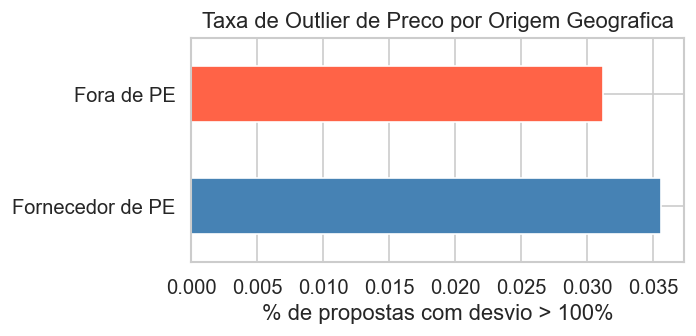

In [44]:
taxa_outlier_geo = df.groupby('fornecedor_fora_pe')['outlier_preco'].mean() * 100
taxa_outlier_geo.index = [fora_pe_labels[k] for k in taxa_outlier_geo.index]

fig, ax = plt.subplots(figsize=(6, 3))
taxa_outlier_geo.plot(kind='barh', ax=ax, color=['steelblue', 'tomato'])
ax.set_xlabel('% de propostas com desvio > 100%')
ax.set_title('Taxa de Outlier de Preco por Origem Geografica')
plt.tight_layout()
plt.show()

---
### 9. Análise por Modalidade Licitatória

A modalidade licitatória determina o rito processual e o nível de competição esperado.

1. **Volume por modalidade**: quais modalidades concentram mais propostas?
2. **Desvio de preço por modalidade**: modalidades com menos concorrência tendem a ter
   maior sobrepreço?
3. **Fornecedor único por modalidade**: a taxa de `fornecedor_unico` varia por modalidade?
   Modalidades de Dispensa e Inexigibilidade têm naturalmente alta taxa, mas em Pregão
   Eletrônico é um sinal de alerta.
4. **Heatmap de risco**: visualização cruzada de 5 indicadores de risco por modalidade,
   normalizada por coluna para comparação relativa entre modalidades.

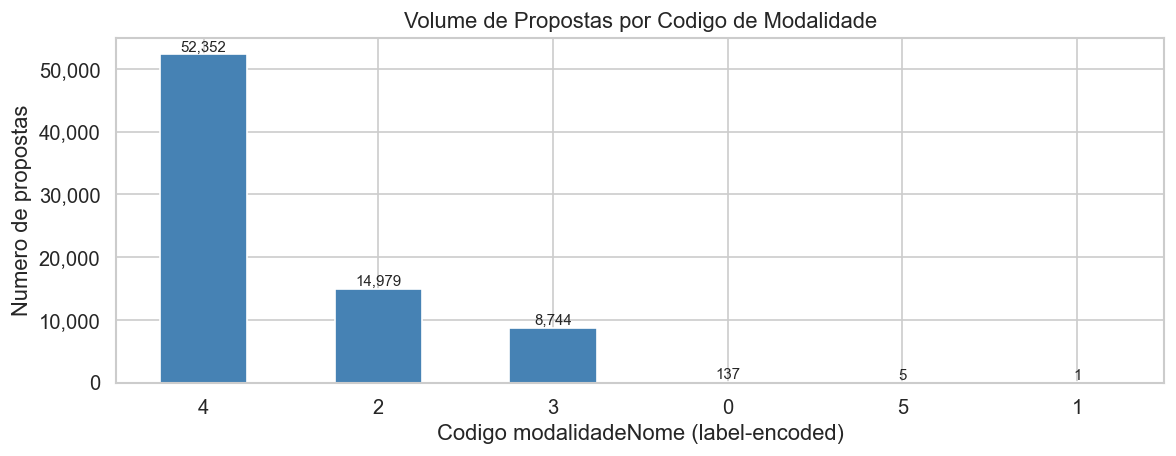

In [45]:
modal_counts = df['modalidadeNome'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
modal_counts.plot(kind='bar', ax=ax, color='steelblue', rot=0)
ax.set_title('Volume de Propostas por Codigo de Modalidade')
ax.set_xlabel('Codigo modalidadeNome (label-encoded)')
ax.set_ylabel('Numero de propostas')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

In [46]:
modal_stats = df.groupby('modalidadeNome').agg(
    n_propostas=('desvio_item_estimado', 'count'),
    desvio_mediana=('desvio_item_estimado', 'median'),
    desvio_media=('desvio_item_estimado', 'mean'),
    taxa_outlier=('outlier_preco', 'mean'),
    taxa_forn_unico=('fornecedor_unico', 'mean'),
    taxa_empresa_nova=('empresa_nova', 'mean'),
    taxa_fora_pe=('fornecedor_fora_pe', 'mean')
).sort_values('n_propostas', ascending=False)

modal_stats[['taxa_outlier','taxa_forn_unico','taxa_empresa_nova','taxa_fora_pe']] *= 100

print('Estatisticas por Modalidade:')
modal_stats.round(3)

Estatisticas por Modalidade:


,n_propostas,desvio_mediana,desvio_media,taxa_outlier,taxa_forn_unico,taxa_empresa_nova,taxa_fora_pe
modalidadeNome,,,,,,,
4,52352,-0.267,-0.295,0.040,94.277,6.493,60.926
2,14979,-0.014,-0.154,0.027,80.052,11.843,53.742
3,8744,0.000,-0.021,0.000,79.323,0.480,92.578
0,137,-0.174,-0.178,0.000,78.832,0.730,42.336
5,5,-0.055,-0.114,0.000,100.000,0.000,100.000
1,1,0.000,0.000,0.000,100.000,0.000,100.000


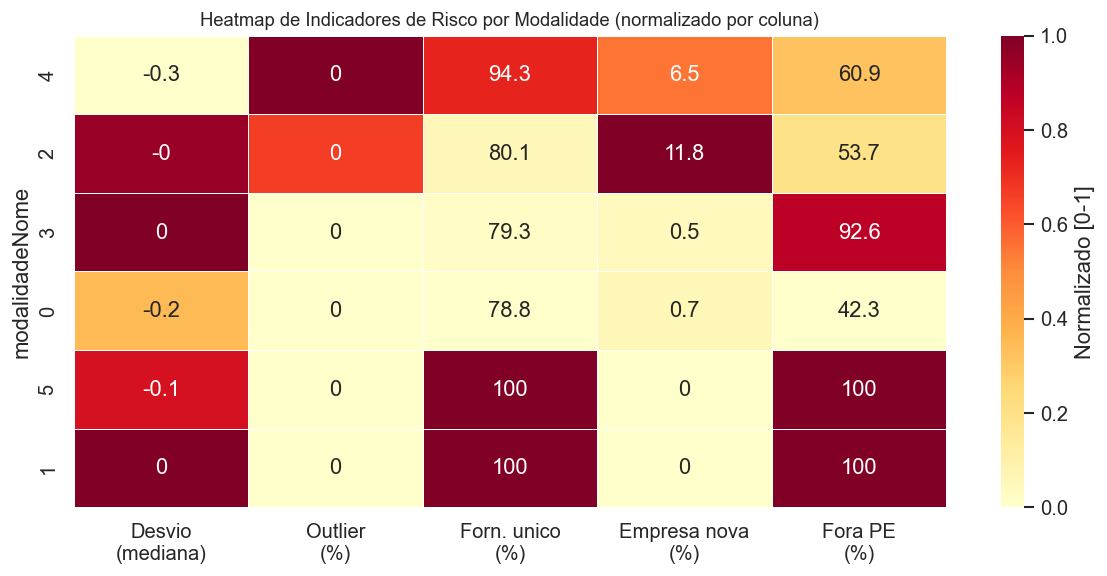

In [47]:
risk_cols   = ['desvio_mediana','taxa_outlier','taxa_forn_unico','taxa_empresa_nova','taxa_fora_pe']
risk_labels = ['Desvio\n(mediana)','Outlier\n(%)','Forn. unico\n(%)','Empresa nova\n(%)','Fora PE\n(%)']

risk_df   = modal_stats[risk_cols].copy()
risk_norm = (risk_df - risk_df.min()) / (risk_df.max() - risk_df.min() + 1e-9)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(risk_norm, annot=risk_df.round(1), fmt='g',
            cmap='YlOrRd', ax=ax, xticklabels=risk_labels,
            linewidths=0.5, cbar_kws={'label': 'Normalizado [0-1]'})
ax.set_title('Heatmap de Indicadores de Risco por Modalidade (normalizado por coluna)', fontsize=11)
plt.tight_layout()
plt.show()

---
### 10. Síntese dos Achados da EDA

In [48]:
print('=' * 65)
print('SINTESE DA EDA - NB07')
print('=' * 65)

print('\n--- Dataset ---')
print(f'Total de propostas:             {len(df):>10,}')
n_orgaos = df['orgaoEntidadeCnpj'].nunique()
n_forn   = df['cnpj_forn_norm'].nunique()
print(f'Orgaos compradores:             {n_orgaos:>10,}')
print(f'Fornecedores unicos:            {n_forn:>10,}')
print(f'Periodo coberto:                2023 - 2024')

print('\n--- Preco ---')
med_glob  = df['desvio_item_estimado'].median()
mean_glob = df['desvio_item_estimado'].mean()
pct_50  = (df['desvio_item_estimado'] > 0.5).mean() * 100
pct_100 = (df['desvio_item_estimado'] > 1.0).mean() * 100
print(f'Desvio mediano global:          {med_glob:>10.4f}')
print(f'Desvio medio global:            {mean_glob:>10.4f}')
print(f'Propostas com desvio > 50%:     {pct_50:>9.1f}%')
print(f'Propostas com desvio > 100%:    {pct_100:>9.1f}%')

print('\n--- Eleitoral ---')
pct_pre  = df['pre_eleitoral_180d'].mean() * 100
d_pre_v  = df.loc[df['pre_eleitoral_180d']==1,'desvio_item_estimado'].median()
d_fora_v = df.loc[df['pre_eleitoral_180d']==0,'desvio_item_estimado'].median()
print(f'Propostas pre-eleitorais <=180d: {pct_pre:>9.1f}%')
print(f'Desvio mediano pre-eleitoral:   {d_pre_v:>10.4f}')
print(f'Desvio mediano fora eleitoral:  {d_fora_v:>10.4f}')
print(f'p-value Mann-Whitney:           {pval_u:>10.4f}')

print('\n--- Geografico ---')
pct_fora_pe = df['fornecedor_fora_pe'].mean() * 100
print(f'Fornecedores fora de PE:        {pct_fora_pe:>9.1f}%')
print(f'Desvio mediano forn. PE:        {g_pe.median():>10.4f}')
print(f'Desvio mediano forn. fora PE:   {g_fora.median():>10.4f}')
print(f'p-value Mann-Whitney:           {pval_geo:>10.4f}')

print('\n--- Perfil de Fornecedores ---')
pct_unico  = df['fornecedor_unico'].mean() * 100
pct_fisica = (df['tipo_fornecedor']==0).mean() * 100
pct_nova   = df['empresa_nova'].mean() * 100
pct_micro  = (df['porte']==1).mean() * 100
print(f'Fornecedor unico (item):        {pct_unico:>9.1f}%')
print(f'Pessoas fisicas:                {pct_fisica:>9.1f}%')
print(f'Empresas novas (<1 ano):        {pct_nova:>9.1f}%')
print(f'Micro empresas (porte=1):       {pct_micro:>9.1f}%')

print('\n' + '=' * 65)

SINTESE DA EDA - NB07

--- Dataset ---
Total de propostas:                 76,218
Orgaos compradores:                    103
Fornecedores unicos:                 9,447
Periodo coberto:                2023 - 2024

--- Preco ---
Desvio mediano global:             -0.1667
Desvio medio global:               -0.2354
Propostas com desvio > 50%:           0.1%
Propostas com desvio > 100%:          0.0%

--- Eleitoral ---
Propostas pre-eleitorais <=180d:      59.1%
Desvio mediano pre-eleitoral:      -0.1977
Desvio mediano fora eleitoral:     -0.1162
p-value Mann-Whitney:               0.0000

--- Geografico ---
Fornecedores fora de PE:             63.1%
Desvio mediano forn. PE:           -0.1976
Desvio mediano forn. fora PE:      -0.1490
p-value Mann-Whitney:               0.0000

--- Perfil de Fornecedores ---
Fornecedor unico (item):             89.7%
Pessoas fisicas:                      8.9%
Empresas novas (<1 ano):              6.8%
Micro empresas (porte=1):            28.3%



In [49]:
features_modelo = [
    # Preço
    'desvio_item_estimado',
    # Concorrência
    'n_propostas_item', 'fornecedor_unico',
    # Temporal
    'ano', 'mes', 'trimestre', 'dia_semana',
    # Eleitoral
    'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d',
    # Geográfica
    'fornecedor_fora_pe',
    # Empresa
    'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova',
    'opcao_pelo_mei', 'opcao_pelo_simples',
    'modalidadeNome', 'porte', 'cnae_fiscal',
    'descricao_situacao_cadastral',
]

ausentes = [f for f in features_modelo if f not in df.columns]
if ausentes:
    print(f'AVISO: features ausentes no dataset: {ausentes}')
else:
    print(f'OK - {len(features_modelo)} features de modelagem verificadas.')

shape_modelo = df[features_modelo].shape
print(f'\nShape do subset de modelagem: {shape_modelo}')

# Identificadores para rastreabilidade no NB08 (mapear scores de volta às propostas)
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

import os
os.makedirs('data/load', exist_ok=True)

output_path = 'data/load/dataset_ml_model.csv'
df[identificadores + features_modelo].to_csv(output_path, index=False)
print(f'\nSalvo em {output_path}: {df[identificadores + features_modelo].shape}')

OK - 20 features de modelagem verificadas.

Shape do subset de modelagem: (76218, 20)

Salvo em data/load/dataset_ml_model.csv: (76218, 25)
